# Laporan Praktikum Sistem Pengolahan Digital

**Nama:** Adi Suryadi  
**NIM:**  607022400039  
**Mata Kuliah:** Sistem Pengolahan Digital
**Modul: Modul3**: Sampling dan Kuantisasi

## Jurnal 1
**Soal 1:** Generation of Train of Impulse Function (Comb Function).

**Keterangan Soal 1:**
- `T` adalah periode sampling (jarak waktu antar impuls/sampel), satuan detik.
- Hubungan dengan frekuensi sampling: $f_s = \frac{1}{T}$.
- Jika `T` diperkecil, maka $f_s$ membesar dan titik sampel semakin rapat.
- Jika `T` diperbesar, maka $f_s$ mengecil dan risiko aliasing meningkat.

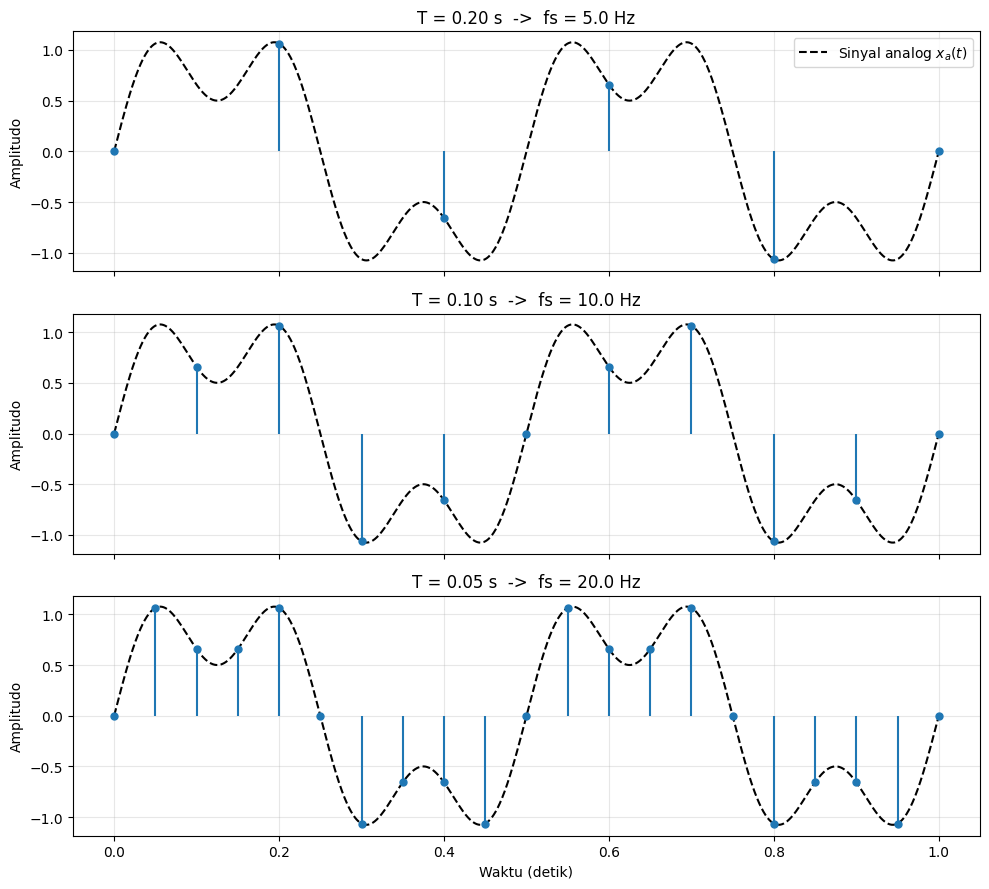

Makna fisis T:
- T adalah periode sampling, yaitu jarak waktu antar impuls/sampel berturut-turut.
- Semakin kecil T -> fs = 1/T semakin besar -> sampel makin rapat (representasi sinyal lebih baik).
- Semakin besar T -> fs lebih kecil -> sampel makin jarang (informasi sinyal bisa hilang/aliasing).


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------------
# 3.1 Generation of a Train of Impulse Function (Comb Function)
# -------------------------------------------------------------
# T = periode sampling (detik)
# fs = frekuensi sampling = 1/T (Hz)

# Sinyal analog contoh (kontinu)
def xa(t):
    return np.sin(2 * np.pi * 2 * t) + 0.5 * np.sin(2 * np.pi * 6 * t)

# Sumbu waktu kontinu untuk visualisasi
t_cont = np.linspace(0, 1, 2000)
x_cont = xa(t_cont)

# Ubah-ubah nilai T untuk melihat pengaruh sampling
T_values = [0.20, 0.10, 0.05]  # detik

fig, axes = plt.subplots(len(T_values), 1, figsize=(10, 9), sharex=True)

for ax, T in zip(axes, T_values):
    fs = 1 / T

    # Waktu diskrit: nT
    n = np.arange(0, int(1 / T) + 1)
    t_s = n * T

    # Nilai sampel x[n] = xa(nT)
    x_s = xa(t_s)

    # Kombinasi visual: sinyal analog + impulse train berbobot (stem)
    ax.plot(t_cont, x_cont, 'k--', linewidth=1.5, label='Sinyal analog $x_a(t)$')
    markerline, stemlines, baseline = ax.stem(
        t_s, x_s, linefmt='C0-', markerfmt='C0o', basefmt=' '
    )
    plt.setp(stemlines, linewidth=1.5)
    plt.setp(markerline, markersize=5)

    ax.set_title(f'T = {T:.2f} s  ->  fs = {fs:.1f} Hz')
    ax.set_ylabel('Amplitudo')
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel('Waktu (detik)')
axes[0].legend(loc='upper right')
plt.tight_layout()
plt.show()

print('Makna fisis T:')
print('- T adalah periode sampling, yaitu jarak waktu antar impuls/sampel berturut-turut.')
print('- Semakin kecil T -> fs = 1/T semakin besar -> sampel makin rapat (representasi sinyal lebih baik).')
print('- Semakin besar T -> fs lebih kecil -> sampel makin jarang (informasi sinyal bisa hilang/aliasing).')

**Keterangan**

- Tiap grafik menunjukkan hasil sampling untuk nilai T yang berbeda.
- T kecil membuat titik sampel lebih rapat, sehingga bentuk sinyal lebih mirip sinyal asli.
- T besar membuat titik sampel lebih jarang, sehingga detail sinyal lebih mudah hilang.

## Jurnal 2
**Soal 1:** Frequency Domain View of Comb Function (C1 dan C2) dan coba bentuk sinyal lain.

**Pembahasan Soal 1 (C1 dan C2):**

Pada comb function, jika impuls periodik di domain waktu berjarak $T$, maka frekuensi dasarnya adalah:

$$f_0 = \frac{1}{T}$$

Komponen spektrum akan muncul pada **kelipatan frekuensi dasar**:
- C1: $k f_{0,1}$
- C2: $k f_{0,2}$

dengan $k = 1,2,3,\dots$.

Semakin rapat impuls di waktu (T makin kecil), maka $f_0$ makin besar sehingga jarak antar garis spektrum di domain frekuensi juga makin lebar.

Kelipatan frekuensi yang terbaca C1 (Hz): [  0.  10.  20.  30.  40.  50.  60.  70.  80.  90. 100. 110.]
Kelipatan frekuensi yang terbaca C2 (Hz): [  0.  20.  40.  60.  80. 100. 120. 140. 160. 180. 200. 220.]


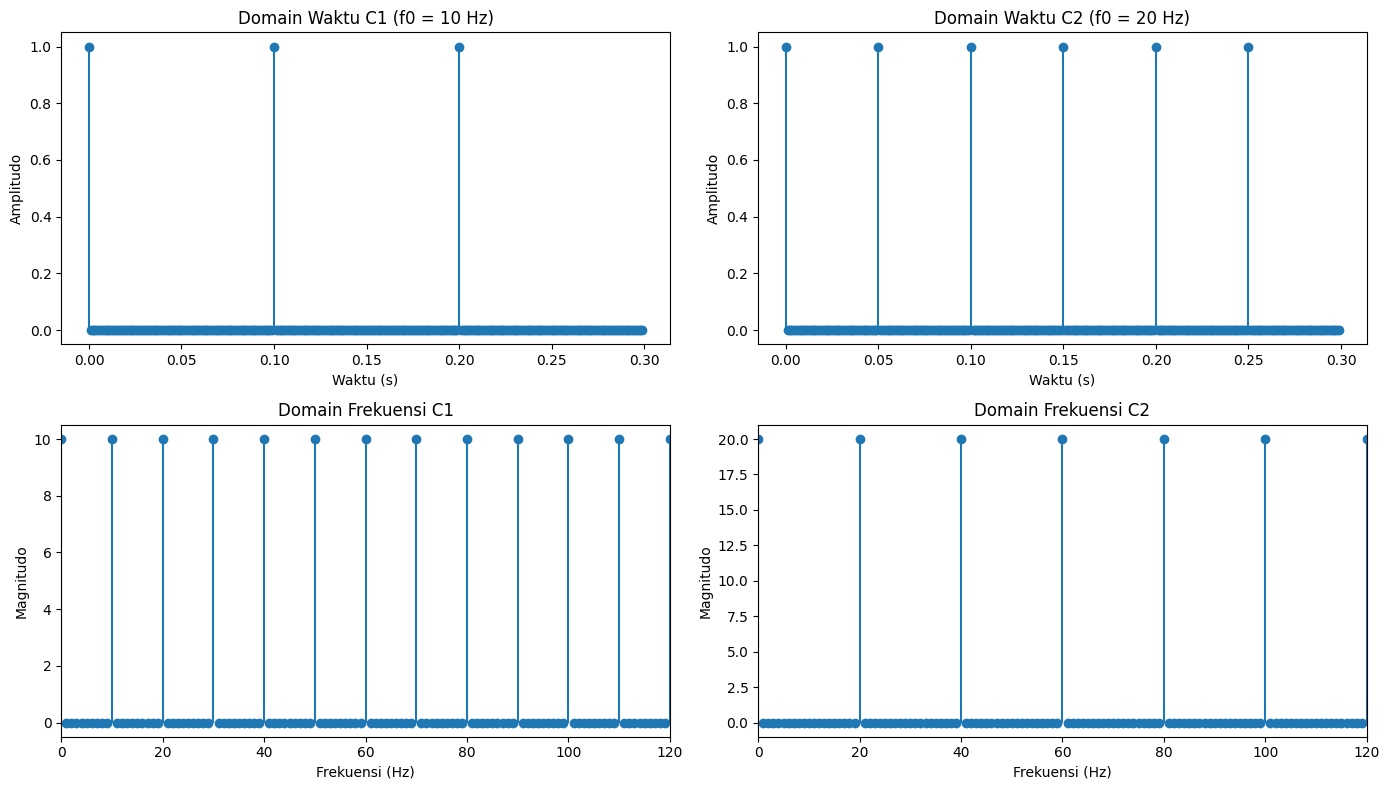

Frekuensi dominan sinyal lain (Hz): [15. 40.]


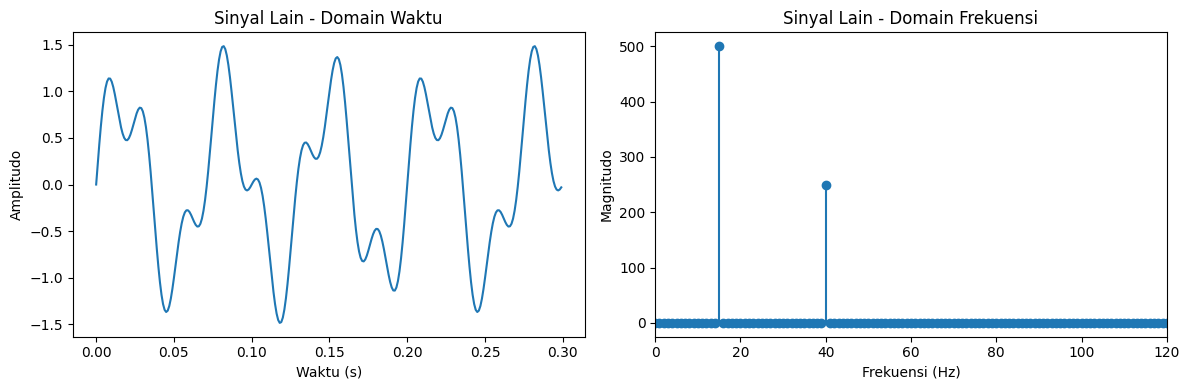

In [2]:
# Jurnal 2 - Frequency Domain View of Comb Function (C1 dan C2)
import numpy as np
import matplotlib.pyplot as plt

fs = 1000       # Hz
dur = 1.0       # detik
N = int(fs * dur)
t = np.arange(N) / fs

# C1 dan C2: comb dengan periode berbeda
f0_c1 = 10      # Hz
f0_c2 = 20      # Hz

C1 = np.zeros(N)
C2 = np.zeros(N)
C1[::int(fs / f0_c1)] = 1
C2[::int(fs / f0_c2)] = 1

# FFT
f = np.fft.rfftfreq(N, d=1/fs)
C1_F = np.abs(np.fft.rfft(C1))
C2_F = np.abs(np.fft.rfft(C2))

# Ambil puncak signifikan
peak_c1 = f[C1_F >= 0.2 * C1_F.max()]
peak_c2 = f[C2_F >= 0.2 * C2_F.max()]

print('Kelipatan frekuensi yang terbaca C1 (Hz):', np.round(peak_c1[:12], 2))
print('Kelipatan frekuensi yang terbaca C2 (Hz):', np.round(peak_c2[:12], 2))

plt.figure(figsize=(14, 8))

plt.subplot(2, 2, 1)
plt.stem(t[:300], C1[:300], basefmt=' ')
plt.title('Domain Waktu C1 (f0 = 10 Hz)')
plt.xlabel('Waktu (s)')
plt.ylabel('Amplitudo')

plt.subplot(2, 2, 2)
plt.stem(t[:300], C2[:300], basefmt=' ')
plt.title('Domain Waktu C2 (f0 = 20 Hz)')
plt.xlabel('Waktu (s)')
plt.ylabel('Amplitudo')

plt.subplot(2, 2, 3)
plt.stem(f, C1_F, basefmt=' ')
plt.xlim(0, 120)
plt.title('Domain Frekuensi C1')
plt.xlabel('Frekuensi (Hz)')
plt.ylabel('Magnitudo')

plt.subplot(2, 2, 4)
plt.stem(f, C2_F, basefmt=' ')
plt.xlim(0, 120)
plt.title('Domain Frekuensi C2')
plt.xlabel('Frekuensi (Hz)')
plt.ylabel('Magnitudo')

plt.tight_layout()
plt.show()

# Coba bentuk sinyal lain
x_lain = np.sin(2*np.pi*15*t) + 0.5*np.sin(2*np.pi*40*t)
X_lain = np.abs(np.fft.rfft(x_lain))
peak_lain = f[X_lain >= 0.2 * X_lain.max()]

print('Frekuensi dominan sinyal lain (Hz):', np.round(peak_lain[:10], 2))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(t[:300], x_lain[:300])
plt.title('Sinyal Lain - Domain Waktu')
plt.xlabel('Waktu (s)')
plt.ylabel('Amplitudo')

plt.subplot(1, 2, 2)
plt.stem(f, X_lain, basefmt=' ')
plt.xlim(0, 120)
plt.title('Sinyal Lain - Domain Frekuensi')
plt.xlabel('Frekuensi (Hz)')
plt.ylabel('Magnitudo')

plt.tight_layout()
plt.show()

**Hasil pengamatan Jurnal 2:**

- C1 (f0 = 10 Hz) terbaca pada kelipatan: 10, 20, 30, 40, ... Hz.
- C2 (f0 = 20 Hz) terbaca pada kelipatan: 20, 40, 60, 80, ... Hz.
- C2 lebih rapat di domain waktu dibanding C1, dan jarak garis spektrumnya lebih lebar.
- Pada sinyal lain (gabungan sinus), puncak dominan muncul di sekitar 15 Hz dan 40 Hz sesuai komponen sinusnya.

### Jurnal 3: Violation of Sampling Theorem (Aliasing)

**Soal 1:** Amati kondisi aliasing saat $f_s < 2f_{max}$ di domain waktu dan frekuensi.

Berdasarkan Teorema Nyquist, syarat agar tidak terjadi aliasing adalah $f_s > 2 f_{max}$. Jika frekuensi sampling lebih rendah dari batas tersebut, maka akan terjadi aliasing di mana frekuensi tinggi tampak sebagai frekuensi rendah.

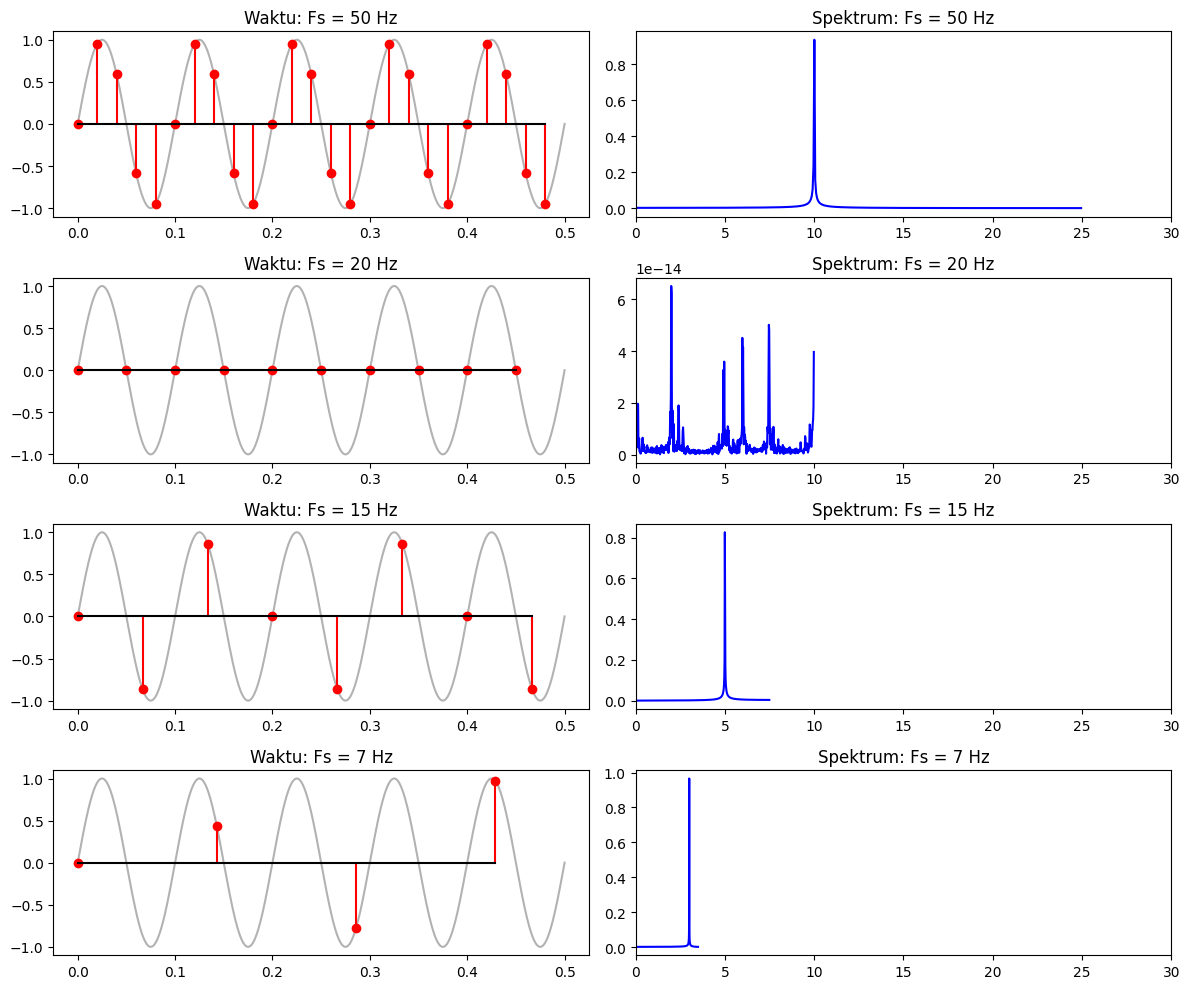

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Parameter
f_sig = 10
duration = 0.5
t_fine = np.linspace(0, duration, 1000)
x_fine = np.sin(2 * np.pi * f_sig * t_fine)
fs_list = [50, 20, 15, 7]

plt.figure(figsize=(12, 10))
for i, fs in enumerate(fs_list):
    # Time domain sampling
    t_s = np.arange(0, duration, 1/fs)
    x_s = np.sin(2 * np.pi * f_sig * t_s)
    
    # Frequency domain via FFT
    N = 1024
    t_fft = np.arange(N) / fs
    x_fft = np.sin(2 * np.pi * f_sig * t_fft)
    X = np.fft.fft(x_fft)
    freqs = np.fft.fftfreq(N, 1/fs)
    
    # Plot Domain Waktu
    plt.subplot(4, 2, 2*i + 1)
    plt.plot(t_fine, x_fine, 'k', alpha=0.3)
    plt.stem(t_s, x_s, 'r', markerfmt='ro', basefmt='k')
    plt.title('Waktu: Fs = {} Hz'.format(fs))
    
    # Plot Spectrum
    plt.subplot(4, 2, 2*i + 2)
    plt.plot(freqs[:N//2], (2.0/N)*np.abs(X[:N//2]), 'b')
    plt.title('Spektrum: Fs = {} Hz'.format(fs))
    plt.xlim(0, 30)

plt.tight_layout()
plt.show()

**Keterangan:**

- Kolom kiri: bentuk sinyal di domain waktu setelah disampling.
- Kolom kanan: spektrum frekuensi hasil sampling.
- Saat Fs makin rendah, bentuk sinyal dan spektrumnya mulai menyimpang dari aslinya (aliasing).

### 3.4 Aliasing in the Time Domain
Membandingkan sinyal asli dengan hasil sampling pada beberapa nilai frekuensi sampling untuk melihat kapan aliasing terjadi.

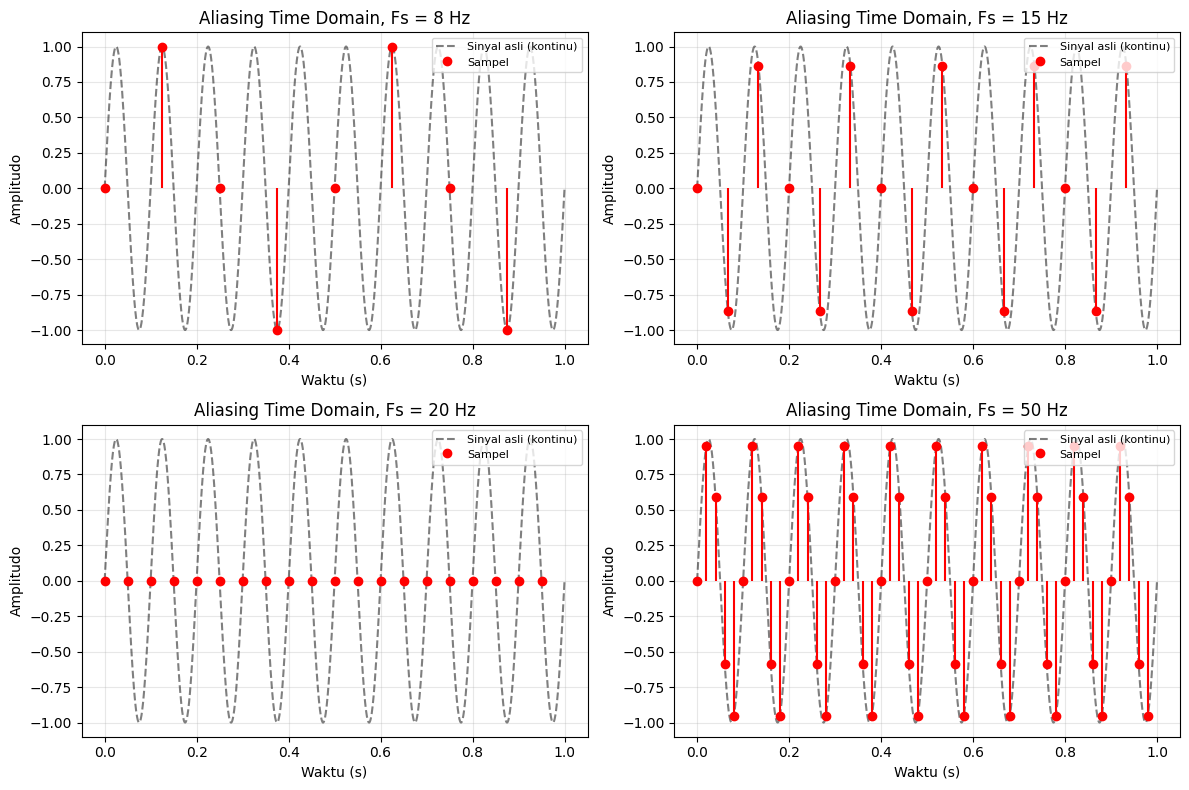

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Sinyal acuan kontinu untuk visualisasi
f_sig = 10  # Hz
dur = 1.0
t_cont = np.linspace(0, dur, 2000)
x_cont = np.sin(2 * np.pi * f_sig * t_cont)

# Coba beberapa nilai Fs (ada yang di bawah/di atas Nyquist = 2*f_sig = 20 Hz)
fs_list = [8, 15, 20, 50]

plt.figure(figsize=(12, 8))
for i, fs_i in enumerate(fs_list):
    t_s = np.arange(0, dur, 1 / fs_i)
    x_s = np.sin(2 * np.pi * f_sig * t_s)

    plt.subplot(2, 2, i + 1)
    plt.plot(t_cont, x_cont, 'k--', alpha=0.5, label='Sinyal asli (kontinu)')
    plt.stem(t_s, x_s, linefmt='r-', markerfmt='ro', basefmt=' ', label='Sampel')
    plt.title(f'Aliasing Time Domain, Fs = {fs_i} Hz')
    plt.xlabel('Waktu (s)')
    plt.ylabel('Amplitudo')
    plt.grid(alpha=0.3)
    plt.legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()

**Keterangan**

- Garis putus-putus hitam adalah sinyal acuan.
- Titik merah adalah hasil sampling.
- Jika Fs cukup tinggi, titik mengikuti bentuk sinyal acuan; jika rendah, bentuk yang terlihat bisa salah.

### 3.4 Illustration of Aliasing in Frequency Domain
Menampilkan spektrum dua sinyal sinus ($f_1=5$ Hz dan $f_2=15$ Hz) pada beberapa nilai $F_s$ untuk melihat lipatan spektrum (aliasing).

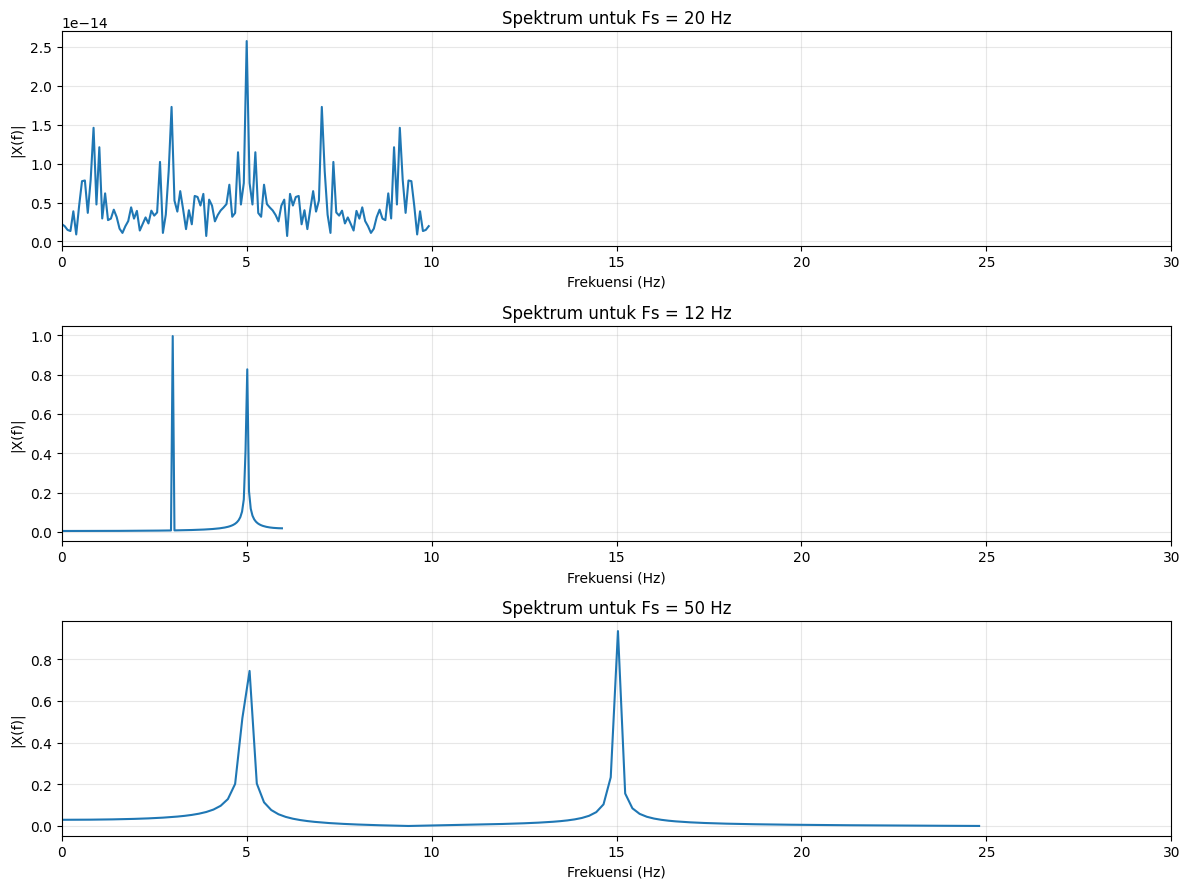

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq

# Dua komponen frekuensi sinyal
f1 = 5
f2 = 15
N = 256
fs_list = [20, 12, 50]  # 12 Hz akan aliasing karena Nyquist = 6 Hz

plt.figure(figsize=(12, 9))
for i, fs_i in enumerate(fs_list):
    T = 1 / fs_i
    t = np.linspace(0, N * T, N, endpoint=False)
    x = np.sin(2 * np.pi * f1 * t) + np.sin(2 * np.pi * f2 * t)

    X = fft(x)
    f_axis = fftfreq(N, T)[:N // 2]
    mag = 2 / N * np.abs(X[:N // 2])

    plt.subplot(len(fs_list), 1, i + 1)
    plt.plot(f_axis, mag, color='C0')
    plt.title(f'Spektrum untuk Fs = {fs_i} Hz')
    plt.xlabel('Frekuensi (Hz)')
    plt.ylabel('|X(f)|')
    plt.xlim(0, max(30, fs_i / 2 + 5))
    plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Keterangan sederhana grafik Aliasing Frequency Domain:**

- Grafik menunjukkan puncak frekuensi komponen sinyal.
- Saat Fs rendah, puncak frekuensi bisa bergeser/lipat ke posisi lain.
- Saat Fs tinggi, puncak frekuensi terlihat di posisi yang benar.

## Jurnal 4: Hearing Aliasing

**Soal 1:** Bandingkan spektrum saat $f_s$ rendah dan saat $f_s = 8000$ Hz.

Kode ini membandingkan spektrum sinyal saat terjadi aliasing (pada $f_s$ rendah) dan saat tidak terjadi aliasing (pada $f_s = 8000$ Hz).

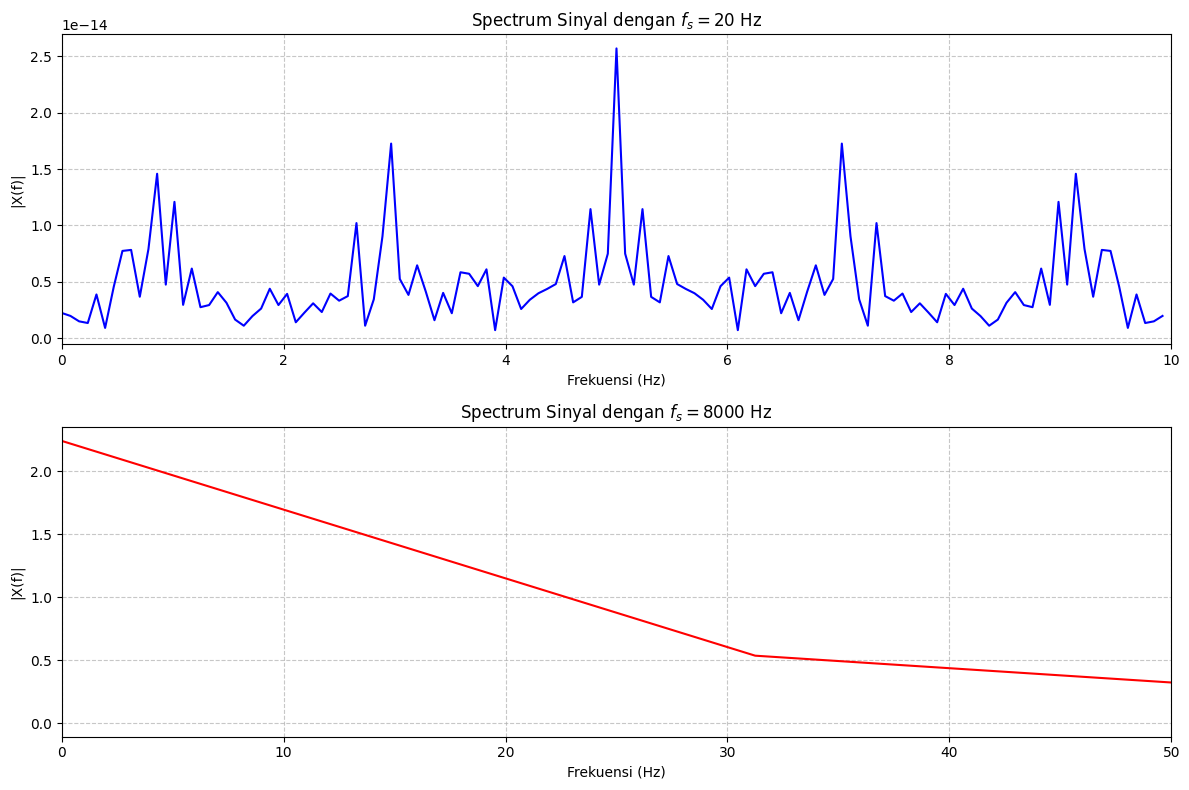

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq

# Step 1: Inisialisasi Parameter
f1 = 5   # Frekuensi sinyal pertama (Hz)
f2 = 15  # Frekuensi sinyal kedua (Hz)
# Menambahkan 8000 ke dalam daftar sampling frequency
fs_list = [20, 8000] 
N = 256  # Jumlah sampel

plt.figure(figsize=(12, 8))

for i, fs in enumerate(fs_list):
    T = 1/fs
    # Membuat vektor waktu
    t = np.linspace(0, N*T, N, endpoint=False)
    
    # Generate Sinyal: Campuran dua gelombang sinus
    x = np.sin(2*np.pi*f1*t) + np.sin(2*np.pi*f2*t)
    
    # Transformasi Fourier (FFT)
    X = fft(x)
    f_axis = fftfreq(N, T)[0:N//2]
    
    # Plotting Spectrum
    plt.subplot(2, 1, i+1)
    plt.plot(f_axis, 2/N * np.abs(X[0:N//2]), color='blue' if fs==20 else 'red')
    plt.xlabel('Frekuensi (Hz)')
    plt.ylabel('|X(f)|')
    plt.title(f'Spectrum Sinyal dengan $f_s = {fs}$ Hz')
    
    # Menambahkan grid untuk mempermudah pembacaan
    plt.grid(True, linestyle='--', alpha=0.7)
    
    # Batasi tampilan sumbu X agar puncak terlihat jelas (terutama untuk fs=8000)
    if fs == 8000:
        plt.xlim(0, 50) # Zoom ke frekuensi rendah agar 5Hz dan 15Hz terlihat
    else:
        plt.xlim(0, fs/2)

plt.tight_layout()
plt.show()


**Keterangan sederhana grafik Jurnal 4:**

- Grafik atas (Fs rendah) menunjukkan kondisi lebih rentan aliasing.
- Grafik bawah (Fs tinggi) menunjukkan spektrum lebih akurat.
- Semakin tinggi Fs, representasi frekuensi sinyal biasanya semakin baik.

### 3.5 Hearing Aliasing
Contoh audio sederhana untuk mendengar efek aliasing saat $f_s$ rendah.

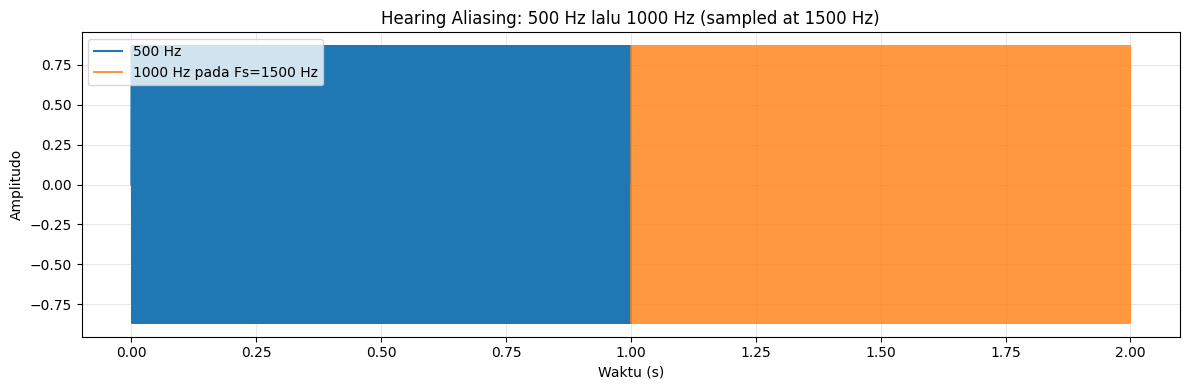

Audio diputar: segmen 1 = 500 Hz, segmen 2 = 1000 Hz (akan terdengar alias).


In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Parameter audio
fs = 1500
dur = 1.0
t = np.arange(0, dur, 1 / fs)

# Dua frekuensi uji
f_low = 500
f_high = 1000  # akan ter-alias karena Nyquist = 750 Hz

x1 = np.sin(2 * np.pi * f_low * t)
x2 = np.sin(2 * np.pi * f_high * t)
x = np.concatenate([x1, x2])

plt.figure(figsize=(12, 4))
plt.plot(np.arange(len(x1)) / fs, x1, label='500 Hz')
plt.plot(np.arange(len(x2)) / fs + dur, x2, label='1000 Hz pada Fs=1500 Hz', alpha=0.8)
plt.xlabel('Waktu (s)')
plt.ylabel('Amplitudo')
plt.title('Hearing Aliasing: 500 Hz lalu 1000 Hz (sampled at 1500 Hz)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

try:
    import sounddevice as sd
    sd.play(x, fs)
    print('Audio diputar: segmen 1 = 500 Hz, segmen 2 = 1000 Hz (akan terdengar alias).')
except Exception as e:
    print('sounddevice tidak tersedia/aktif. Jalankan `pip install sounddevice` jika ingin memutar audio.')
    print('Detail:', e)

**Keterangan sederhana grafik Hearing Aliasing:**

- Grafik menampilkan dua bagian sinyal: 500 Hz lalu 1000 Hz pada Fs yang sama.
- Bagian frekuensi tinggi bisa terdengar tidak sesuai karena efek aliasing.
- Tujuannya untuk menunjukkan aliasing tidak hanya terlihat di grafik, tapi juga bisa terdengar.

### 3.6 Mid-Tread Quantizer
Transfer characteristic quantizer mid-tread untuk beberapa nilai bit.

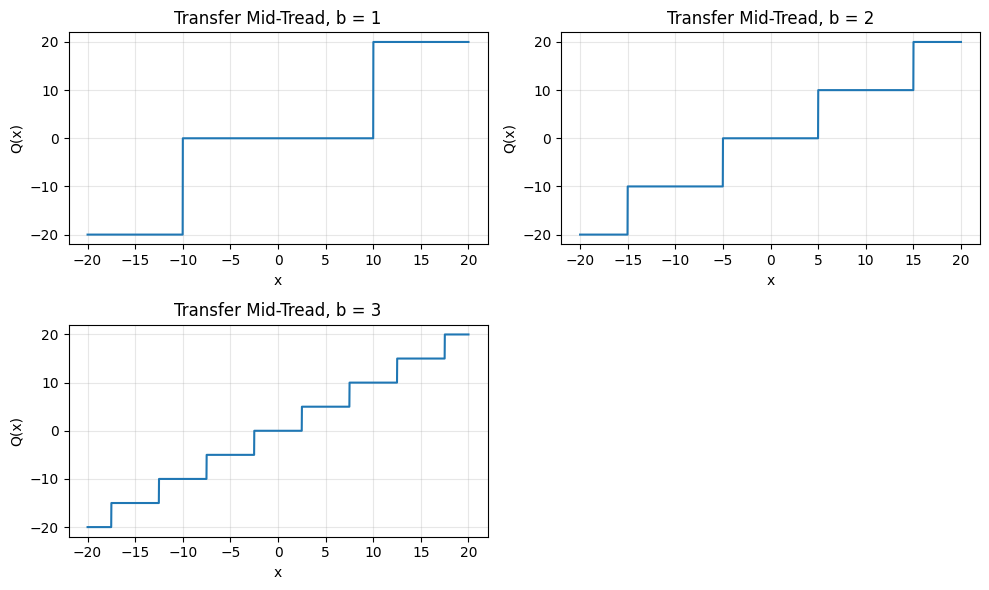

In [8]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-20, 20, 2000)
DR = np.max(x) - np.min(x)
bits = [1, 2, 3]

plt.figure(figsize=(10, 6))
for i, b in enumerate(bits):
    L = 2 ** b
    q = DR / L

    # Mid-tread quantizer
    y = np.sign(x) * q * np.floor((np.abs(x) / q) + 0.5)

    plt.subplot(2, 2, i + 1)
    plt.plot(x, y)
    plt.xlabel('x')
    plt.ylabel('Q(x)')
    plt.title(f'Transfer Mid-Tread, b = {b}')
    plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Keterangan**

- Grafik menunjukkan bentuk tangga hasil kuantisasi.
- Bit kecil menghasilkan tangga kasar, bit besar menghasilkan tangga lebih halus.
- Semakin besar bit, hasil kuantisasi semakin mendekati sinyal asli.

### Jurnal 5 (Panduan Singkat)

**Soal 1:** Plot nilai error kuantisasi $e[n] = x[n] - x_q[n]$.
**Soal 2:** Ilustrasikan bahwa error kuantisasi mendekati distribusi uniform.

Tujuan: menganalisis error kuantisasi pada sinyal sawtooth dengan quantizer mid-tread.

Yang dikerjakan di kode:
1. Plot sinyal input dan sinyal hasil kuantisasi untuk beberapa bit ($b=1,2,4,8$).
2. Hitung error kuantisasi dengan rumus $e[n] = x[n] - x_q[n]$.
3. Plot sinyal error terhadap waktu untuk melihat perubahan besar error saat $b$ berubah.
4. Plot histogram error untuk mengecek apakah distribusinya mendekati uniform.

Poin analisis yang bisa kamu tulis:
- Saat $b$ naik, langkah kuantisasi $q$ mengecil sehingga error makin kecil.
- Nilai rata-rata error mendekati nol.
- Variansi error simulasi mendekati nilai teoritis uniform, yaitu $q^2/12$.

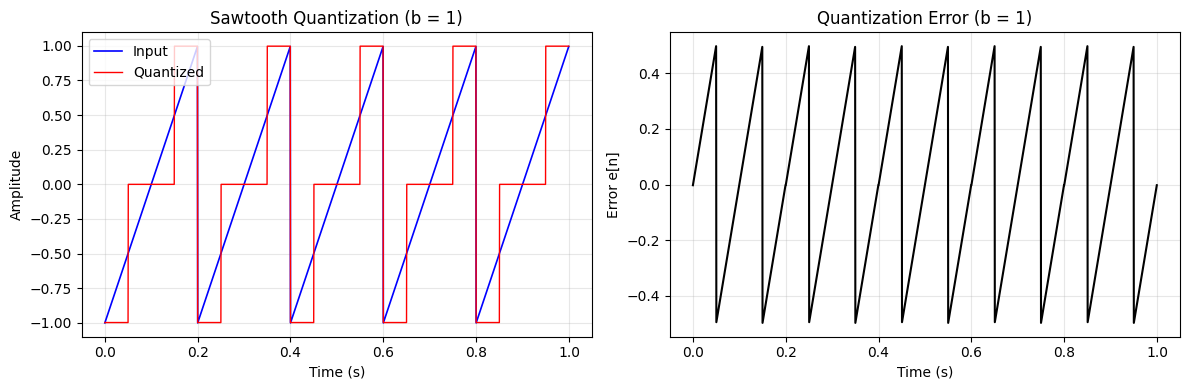

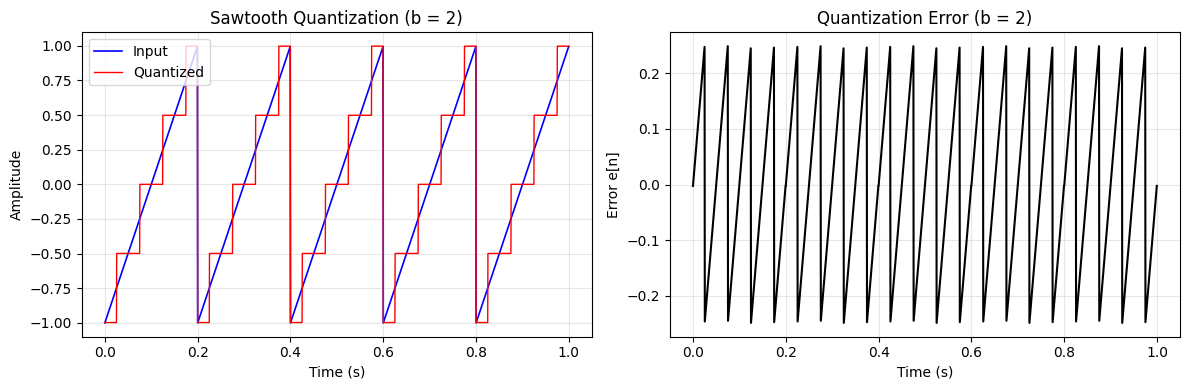

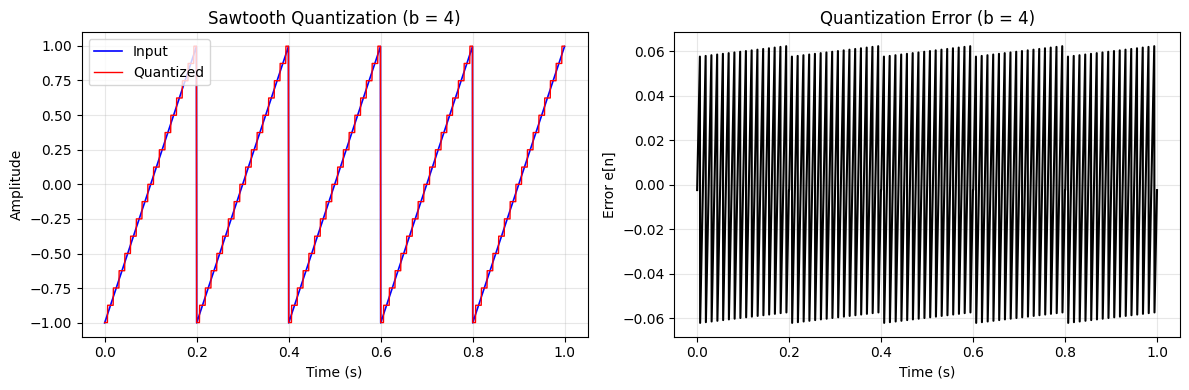

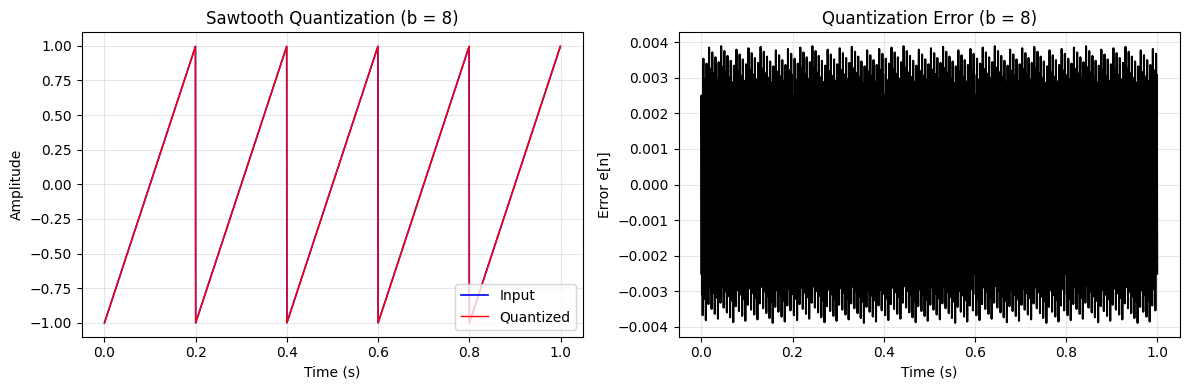

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Input signal: sawtooth
t = np.linspace(0, 1, 2000, endpoint=False)
x = signal.sawtooth(2 * np.pi * 5 * t)

DR = np.max(x) - np.min(x)
bits = [1, 2, 4, 8]

for b in bits:
    L = 2 ** b
    q = DR / L

    # Mid-tread quantization
    xq = np.sign(x) * q * np.floor((np.abs(x) / q) + 0.5)
    e = x - xq

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(t, x, 'b', linewidth=1.2, label='Input')
    plt.plot(t, xq, 'r', linewidth=1.0, label='Quantized')
    plt.xlabel('Time (s)')
    plt.ylabel('Amplitude')
    plt.title(f'Sawtooth Quantization (b = {b})')
    plt.legend()
    plt.grid(alpha=0.3)

    plt.subplot(1, 2, 2)
    plt.plot(t, e, 'k')
    plt.xlabel('Time (s)')
    plt.ylabel('Error e[n]')
    plt.title(f'Quantization Error (b = {b})')
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

**Keterangan**

- Grafik kiri: perbandingan sinyal input dan sinyal setelah kuantisasi.
- Grafik kanan: selisih keduanya (error kuantisasi).
- Saat bit bertambah, selisih/error terlihat makin kecil.

**Soal 2 (Jurnal 5):** Ilustrasi distribusi error kuantisasi (uniform).

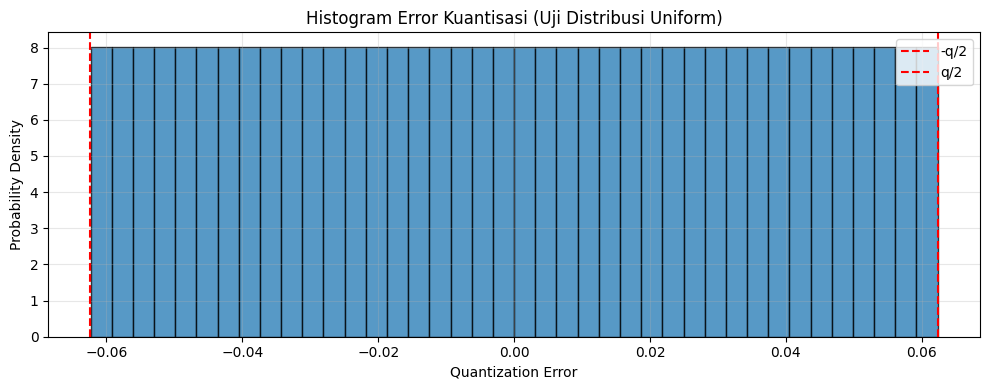

Bit = 4, step q = 0.12484
Rata-rata error = -0.000002 (mendekati 0)
Var(error) teoritis uniform = q^2/12 = 0.001299
Var(error) simulasi         = 0.001297


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Fokus uji uniform error pada salah satu bit-depth (misal b=4)
t = np.linspace(0, 1, 4000, endpoint=False)
x = signal.sawtooth(2 * np.pi * 5 * t)

b = 4
L = 2 ** b
DR = np.max(x) - np.min(x)
q = DR / L

xq = np.sign(x) * q * np.floor((np.abs(x) / q) + 0.5)
e = x - xq

plt.figure(figsize=(10, 4))
plt.hist(e, bins=40, density=True, alpha=0.75, color='tab:blue', edgecolor='black')
plt.axvline(-q/2, color='red', linestyle='--', label='-q/2')
plt.axvline(q/2, color='red', linestyle='--', label='q/2')
plt.xlabel('Quantization Error')
plt.ylabel('Probability Density')
plt.title('Histogram Error Kuantisasi (Uji Distribusi Uniform)')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f'Bit = {b}, step q = {q:.5f}')
print(f'Rata-rata error = {np.mean(e):.6f} (mendekati 0)')
print(f'Var(error) teoritis uniform = q^2/12 = {q**2/12:.6f}')
print(f'Var(error) simulasi         = {np.var(e):.6f}')

**Keterangan**

- Histogram menunjukkan sebaran nilai error kuantisasi.
- Batas merah menandai rentang error teoritis sekitar -q/2 sampai q/2.
- Grafik dipakai untuk melihat apakah error cenderung tersebar merata (uniform).

### 3.7 Mid-Rise Quantizer
Transfer characteristic quantizer mid-rise untuk beberapa nilai bit.

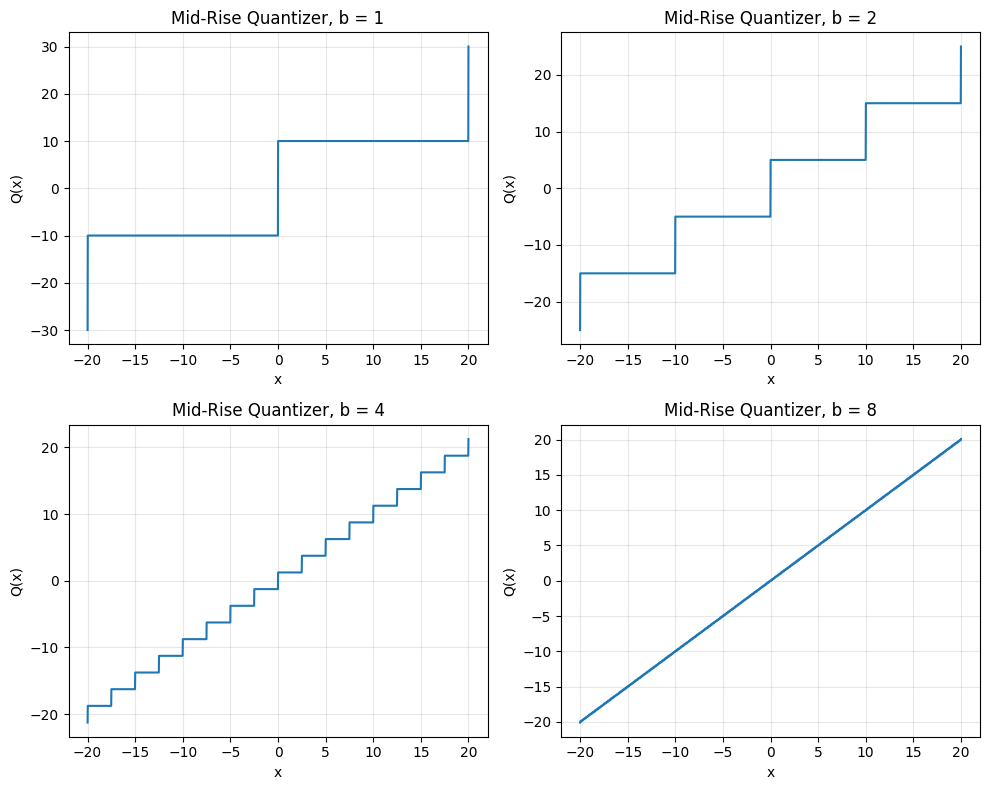

In [11]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-20, 20, 2000)
DR = np.max(x) - np.min(x)
bits = [1, 2, 4, 8]

plt.figure(figsize=(10, 8))
for i, b in enumerate(bits):
    L = 2 ** b
    q = DR / L

    # Mid-rise quantizer
    y = np.sign(x) * q * (np.floor(np.abs(x) / q) + 0.5)

    plt.subplot(2, 2, i + 1)
    plt.plot(x, y)
    plt.xlabel('x')
    plt.ylabel('Q(x)')
    plt.title(f'Mid-Rise Quantizer, b = {b}')
    plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Keterangan sederhana grafik Mid-Rise:**

- Grafik menampilkan karakteristik kuantisasi metode mid-rise.
- Dibanding mid-tread, metode ini tidak punya level tepat di nol.
- Saat bit naik, bentuk tangga makin rapat dan lebih halus.

### Jurnal 6: Perbandingan Mid-Tread vs Mid-Rise

**Soal 1:** Bandingkan hasil kuantisasi metode mid-tread dan mid-rise untuk beberapa nilai bit.

**Soal 2:** Bandingkan error (MSE) mid-tread dan mid-rise, lalu beri kesimpulan metode mana yang lebih baik berdasarkan hasil grafik.

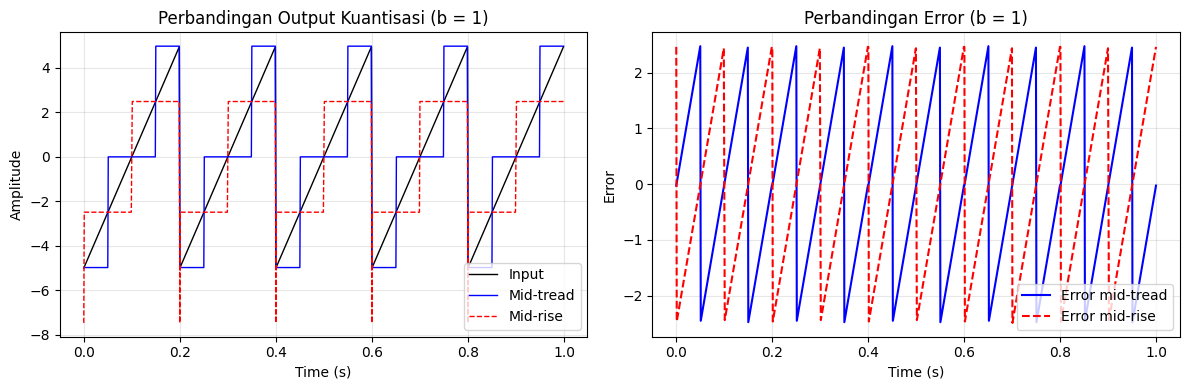

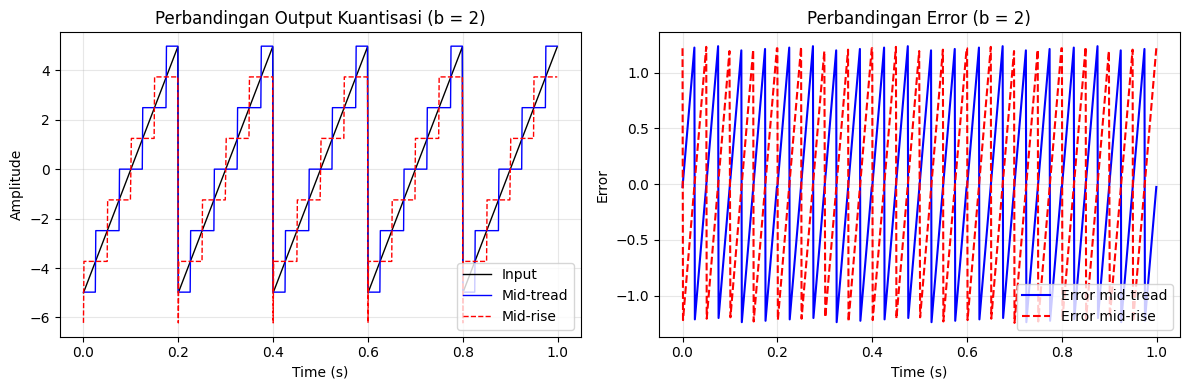

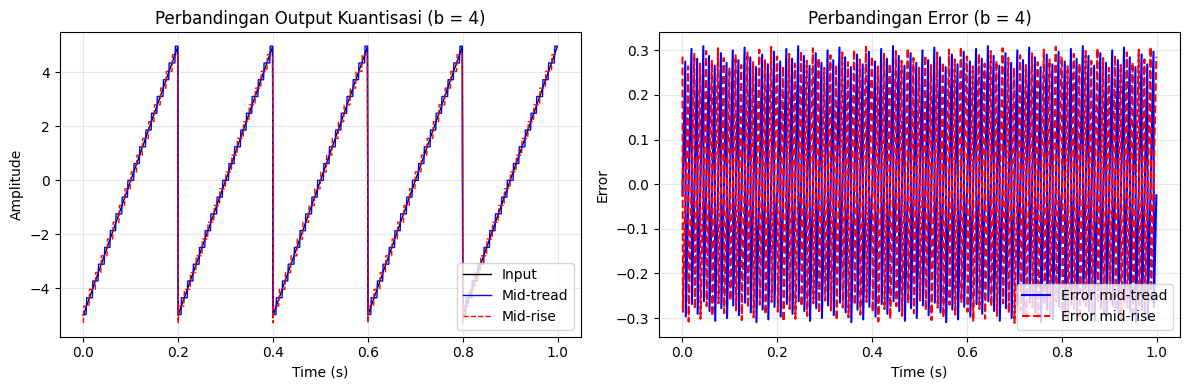

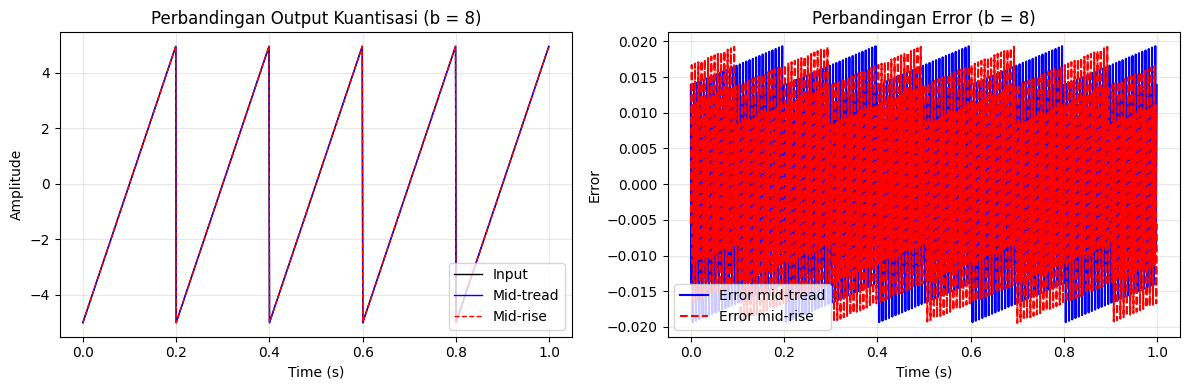

MSE Mid-tread per bit : [2.052190625000002, 0.5130500000000005, 0.032068554687500035, 0.00012621707916259505]
MSE Mid-rise  per bit : [2.057911875, 0.5143248437499999, 0.032089931640624986, 0.00012390933990478632]

Komentar Jurnal 6:
- Mid-tread memiliki level nol (ada dead-zone di sekitar 0), sedangkan mid-rise tidak melewati nol.
- Mid-rise cenderung memberi offset kecil di sekitar nol karena level kuantisasi berada di antara langkah.
- Saat bit bertambah, keduanya semakin mendekati sinyal asli dan error (MSE) sama-sama menurun.


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Input signal
t = np.linspace(0, 1, 1000, endpoint=False)
x = 5 * signal.sawtooth(2 * np.pi * 5 * t)
DR = np.max(x) - np.min(x)
bits = [1, 2, 4, 8]

mse_tread = []
mse_rise = []

for b in bits:
    L = 2 ** b
    q = DR / L

    # Mid-tread
    y_tread = np.sign(x) * q * np.floor((np.abs(x) / q) + 0.5)
    e_tread = x - y_tread
    mse_tread.append(np.mean(e_tread ** 2))

    # Mid-rise
    y_rise = np.sign(x) * q * (np.floor(np.abs(x) / q) + 0.5)
    e_rise = x - y_rise
    mse_rise.append(np.mean(e_rise ** 2))

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(t, x, 'k', linewidth=1, label='Input')
    plt.plot(t, y_tread, 'b', linewidth=1, label='Mid-tread')
    plt.plot(t, y_rise, 'r--', linewidth=1, label='Mid-rise')
    plt.title(f'Perbandingan Output Kuantisasi (b = {b})')
    plt.xlabel('Time (s)')
    plt.ylabel('Amplitude')
    plt.legend()
    plt.grid(alpha=0.3)

    plt.subplot(1, 2, 2)
    plt.plot(t, e_tread, 'b', label='Error mid-tread')
    plt.plot(t, e_rise, 'r--', label='Error mid-rise')
    plt.title(f'Perbandingan Error (b = {b})')
    plt.xlabel('Time (s)')
    plt.ylabel('Error')
    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

print('MSE Mid-tread per bit :', [float(v) for v in mse_tread])
print('MSE Mid-rise  per bit :', [float(v) for v in mse_rise])

print('\nKomentar Jurnal 6:')
print('- Mid-tread memiliki level nol (ada dead-zone di sekitar 0), sedangkan mid-rise tidak melewati nol.')
print('- Mid-rise cenderung memberi offset kecil di sekitar nol karena level kuantisasi berada di antara langkah.')
print('- Saat bit bertambah, keduanya semakin mendekati sinyal asli dan error (MSE) sama-sama menurun.')

**Keterangan**

- Grafik kiri: perbandingan sinyal input, output mid-tread, dan output mid-rise.
- Grafik kanan: perbandingan error kuantisasi kedua metode pada bit yang sama.
- Saat bit bertambah, kurva kuantisasi makin mendekati input dan error makin kecil.

### 3.8 Kuantisasi pada File Suara dan Gambar

Bagian ini mencakup:
1. Uniform quantization pada file suara.
2. Kuantisasi citra 256 x 256 hitam-putih untuk beberapa laju bit.

## Jurnal 7
**Soal 1:** Kuantisasi pada file suara dan amati perubahan kualitas saat bit mengecil.

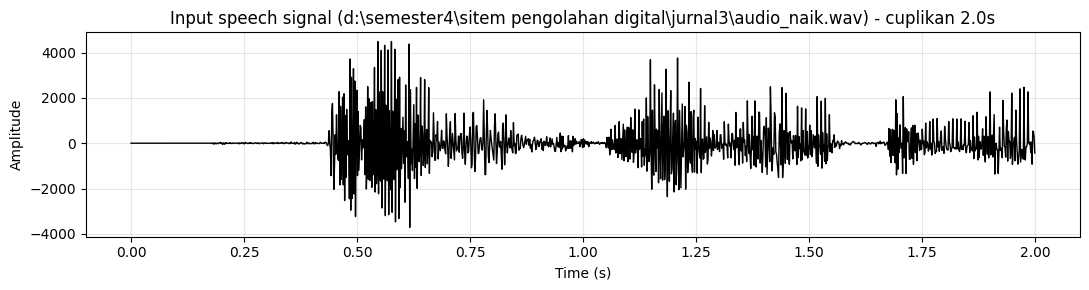

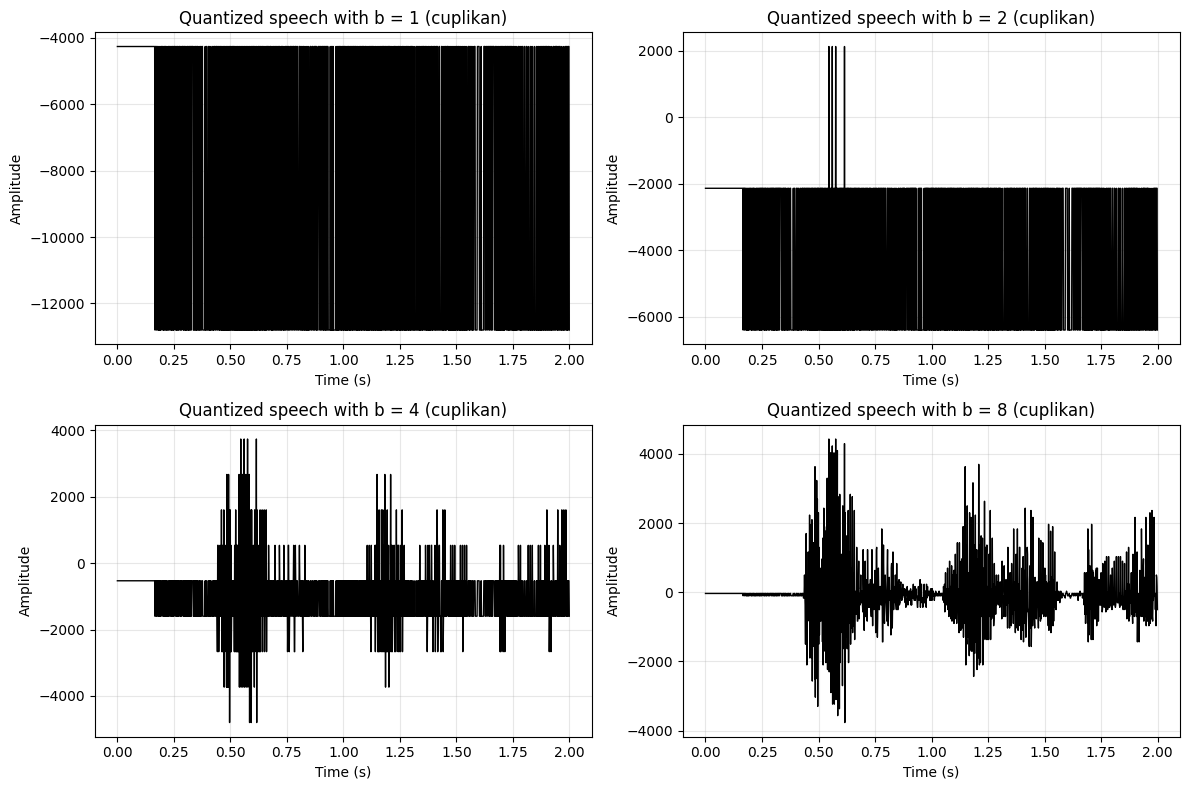

File audio yang dipakai: D:\semester4\sitem pengolahan digital\jurnal3\audio_naik.wav
Durasi audio: 9.06 s | Ditampilkan: 2.0 s | Plot step: 72


In [13]:
# Uniform quantization of speech signal
from scipy.io import wavfile
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Cari file audio secara fleksibel dari beberapa kemungkinan folder kerja
base_dirs = [
    Path.cwd(),
    Path.cwd() / 'jurnal3',
    Path.cwd().parent / 'jurnal3',
]

candidate_names = [
    'hello2.wav',
    'audio_naik.wav',
    'audio_turun.wav',
    'WhatsApp Ptt 2026-03-16 at 17.01.32.wav',
]

candidates = []
for d in base_dirs:
    for name in candidate_names:
        candidates.append(d / name)

# Tambahan fallback: ambil semua file .wav yang ada di base_dirs
for d in base_dirs:
    if d.exists():
        candidates.extend(sorted(d.glob('*.wav')))

# Hilangkan duplikasi sambil mempertahankan urutan
seen = set()
unique_candidates = []
for p in candidates:
    sp = str(p.resolve()) if p.exists() else str(p)
    if sp not in seen:
        unique_candidates.append(p)
        seen.add(sp)

audio_path = None
for p in unique_candidates:
    if p.exists():
        audio_path = p
        break

if audio_path is None:
    searched = '\n'.join(str(p) for p in unique_candidates[:20])
    raise FileNotFoundError(
        'File audio tidak ditemukan. Kandidat yang dicek:\n' + searched +
        '\n\nPastikan salah satu file .wav ada di folder kerja atau folder jurnal3.'
    )

# Step 1: Reading speech waveform
samplerate, x = wavfile.read(str(audio_path))

# Jika stereo -> jadikan mono
if x.ndim > 1:
    x = x.mean(axis=1)

x = x.astype(np.float64)
duration = x.shape[0] / samplerate
t = np.linspace(0, duration, x.shape[0], endpoint=False)

# Ringankan plotting agar tidak freeze di notebook
max_points = 6000
plot_step = max(1, len(x) // max_points)
view_sec = min(2.0, duration)  # tampilkan cuplikan 2 detik pertama
view_n = max(1, int(view_sec * samplerate))

plt.figure(figsize=(11, 3))
plt.plot(t[:view_n:plot_step], x[:view_n:plot_step], 'k', linewidth=1)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title(f'Input speech signal ({audio_path}) - cuplikan {view_sec:.1f}s')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Step 2: Uniform quantization
DR = np.max(x) - np.min(x)
bits = [1, 2, 4, 8]

if DR == 0:
    raise ValueError('Dynamic range audio = 0. File audio berisi nilai konstan, tidak bisa dikuantisasi dengan benar.')

plt.figure(figsize=(12, 8))
for i, b in enumerate(bits):
    L = 2 ** b
    q = DR / L

    # Mid-rise style uniform quantization
    y = np.floor(x / q) * q - (q / 2)

    plt.subplot(2, 2, i + 1)
    plt.plot(t[:view_n:plot_step], y[:view_n:plot_step], 'k', linewidth=1)
    plt.xlabel('Time (s)')
    plt.ylabel('Amplitude')
    plt.title(f'Quantized speech with b = {b} (cuplikan)')
    plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print('File audio yang dipakai:', audio_path.resolve())
print(f'Durasi audio: {duration:.2f} s | Ditampilkan: {view_sec:.1f} s | Plot step: {plot_step}')

**Keterangan:**
- Link untuk vidio https://drive.google.com/file/d/1pSD1rMAIhc_KJw55ueopgwu5XNAZTv2Z/view?usp=drive_link
- Grafik pertama: sinyal suara asli sebelum kuantisasi.
- Empat grafik berikutnya: hasil kuantisasi untuk b = 1, 2, 4, 8.
- Semakin besar nilai bit, bentuk sinyal hasil kuantisasi semakin mirip sinyal asli.

**Soal 2 (Jurnal 7):** Generate gambar 256 x 256 (kolom 0-127 putih, kolom 128-255 hitam), lalu kuantisasi untuk berbagai bit dan amati hasilnya.

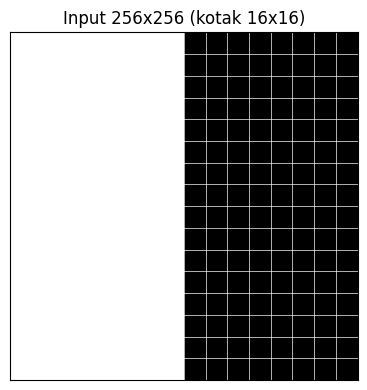

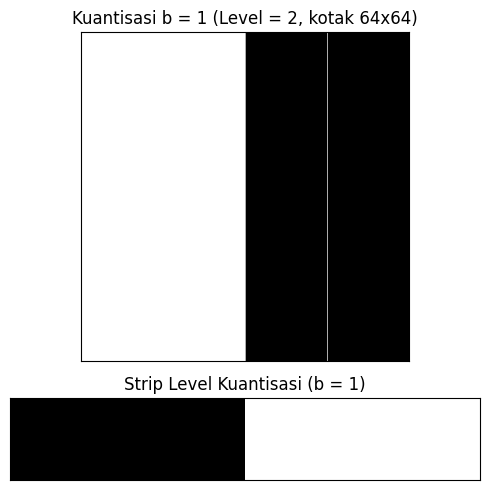

b=1, level teoritis=2, level unik pada gambar=2, kotak=64x64, nilai=[  0. 255.]


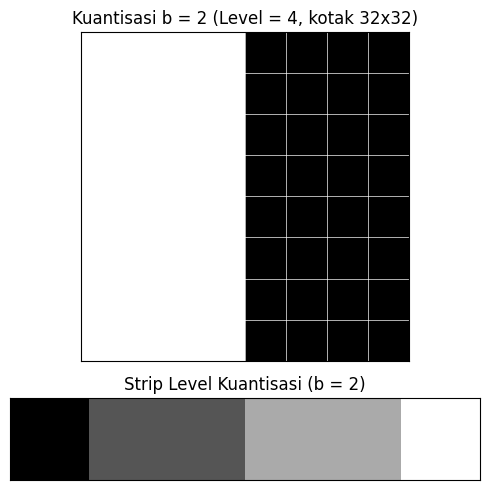

b=2, level teoritis=4, level unik pada gambar=2, kotak=32x32, nilai=[  0. 255.]


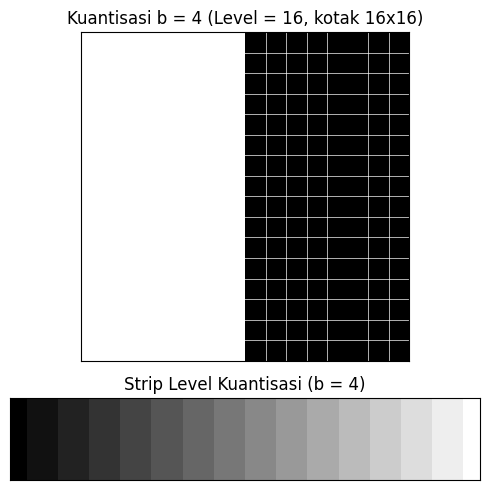

b=4, level teoritis=16, level unik pada gambar=2, kotak=16x16, nilai=[  0. 255.]


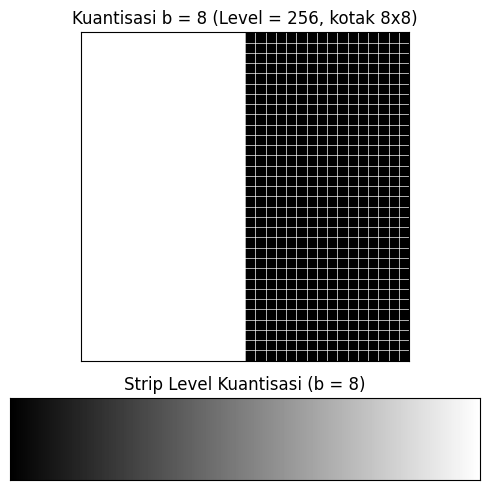

b=8, level teoritis=256, level unik pada gambar=2, kotak=8x8, nilai=[  0. 255.]

Catatan:
- Gambar soal tetap 2 level (0 dan 255), jadi area putih-hitam utamanya tetap sama.
- Tanda kotak sekarang berbeda tiap bit: b kecil lebih kasar, b besar lebih rapat.
- Kenaikan bit juga terlihat pada strip level kuantisasi (gradasi makin rapat).


In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Generate gambar 256x256: kiri putih (255), kanan hitam (0)
img = np.zeros((256, 256), dtype=np.float64)
img[:, :128] = 255
img[:, 128:] = 0

def quantize_image_uniform(x, b):
    levels = 2 ** b
    q = 255.0 / (levels - 1)
    y = np.round(x / q) * q
    return np.clip(y, 0, 255)

def block_view(x, block=16):
    h, w = x.shape
    return x.reshape(h // block, block, w // block, block).mean(axis=(1, 3))

def show_block_grid(ax, block_img, title):
    ax.imshow(block_img, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
    ax.set_title(title)
    ax.set_xticks(np.arange(-0.5, block_img.shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-0.5, block_img.shape[0], 1), minor=True)
    ax.grid(which='minor', color='white', linewidth=0.7, alpha=0.7)
    ax.tick_params(which='both', bottom=False, left=False, labelbottom=False, labelleft=False)

# Urutan bit naik
bits = sorted([1, 2, 4, 8])

# Kepadatan kotak dibuat berbeda per bit agar tanda kotak berubah jelas
block_size_map = {
    1: 64,
    2: 32,
    4: 16,
    8: 8,
}

# Tampilkan input dengan ukuran kotak referensi
fig, ax = plt.subplots(1, 1, figsize=(4, 4))
show_block_grid(ax, block_view(img, block=16), 'Input 256x256 (kotak 16x16)')
plt.tight_layout()
plt.show()

# Tampilkan hasil per bit + strip level kuantisasi
for b in bits:
    qimg = quantize_image_uniform(img, b)
    block_size = block_size_map[b]
    qblock = block_view(qimg, block=block_size)

    # Strip level 0..255 untuk menunjukkan level kuantisasi bertambah saat b naik
    ramp = np.tile(np.arange(256, dtype=np.float64), (32, 1))
    ramp_q = quantize_image_uniform(ramp, b)

    fig, axs = plt.subplots(2, 1, figsize=(5, 5), gridspec_kw={'height_ratios': [4, 1]})
    show_block_grid(
        axs[0],
        qblock,
        f'Kuantisasi b = {b} (Level = {2**b}, kotak {block_size}x{block_size})'
    )
    axs[1].imshow(ramp_q, cmap='gray', vmin=0, vmax=255, aspect='auto', interpolation='nearest')
    axs[1].set_title(f'Strip Level Kuantisasi (b = {b})')
    axs[1].set_xticks([])
    axs[1].set_yticks([])
    plt.tight_layout()
    plt.show()

    print(
        f'b={b}, level teoritis={2**b}, level unik pada gambar={len(np.unique(qimg))}, '
        f'kotak={block_size}x{block_size}, nilai={np.unique(qimg)}'
    )

print('\nCatatan:')
print('- Gambar soal tetap 2 level (0 dan 255), jadi area putih-hitam utamanya tetap sama.')
print('- Tanda kotak sekarang berbeda tiap bit: b kecil lebih kasar, b besar lebih rapat.')
print('- Kenaikan bit juga terlihat pada strip level kuantisasi (gradasi makin rapat).')

**Keterangan:**

- Grafik utama: hasil kuantisasi gambar hitam-putih untuk tiap bit.
- Strip bawah: jumlah level kuantisasi yang tersedia pada bit tersebut.
- Nilai bit yang lebih besar memberi level lebih banyak sehingga transisi intensitas lebih halus.

## Jurnal 8
**Soal 1:** Non-uniform Quantization (Mu-law Companding).
Kuantisasi non-uniform dengan kompresi $\mu$-law sebelum kuantisasi, lalu dekompresi sesudahnya.

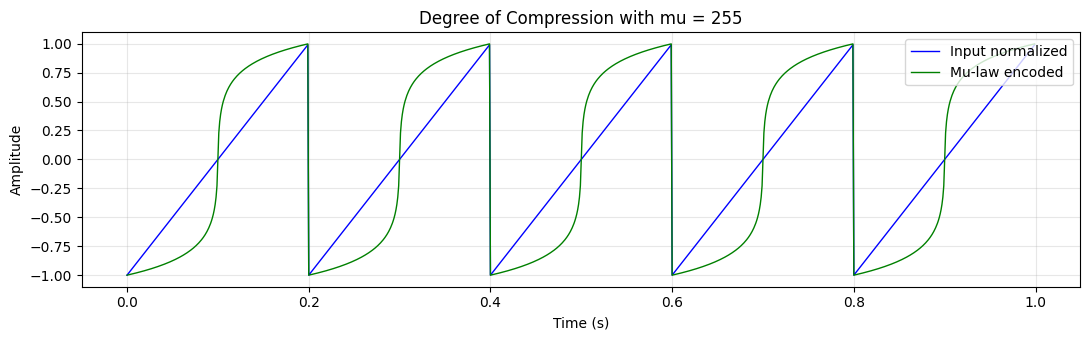

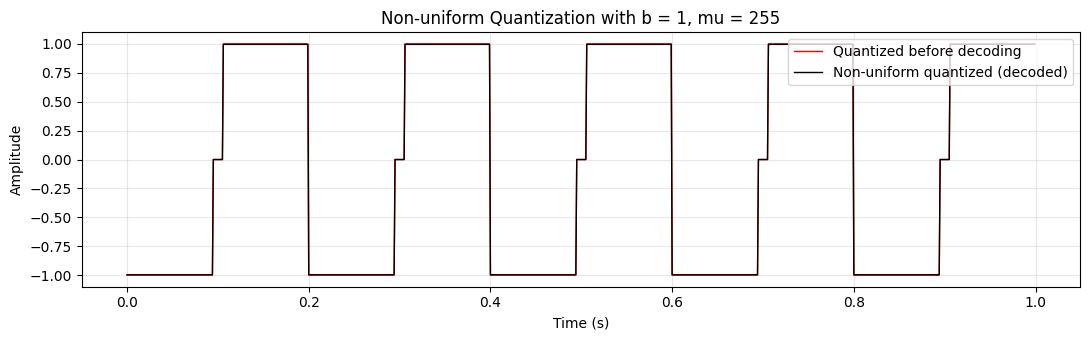

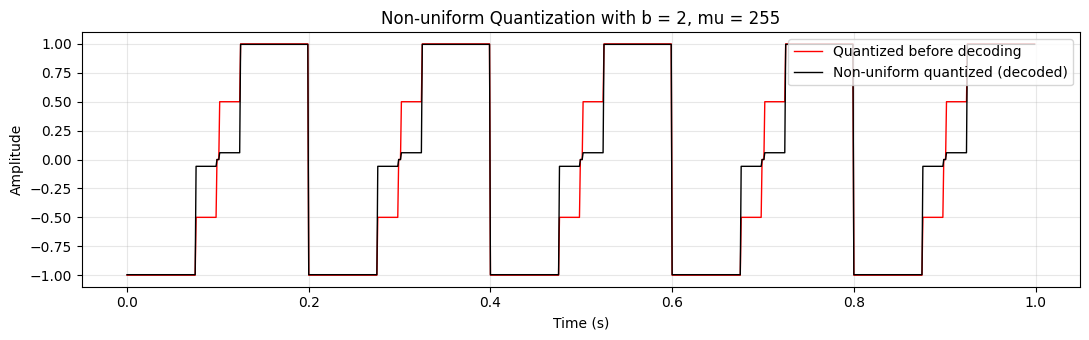

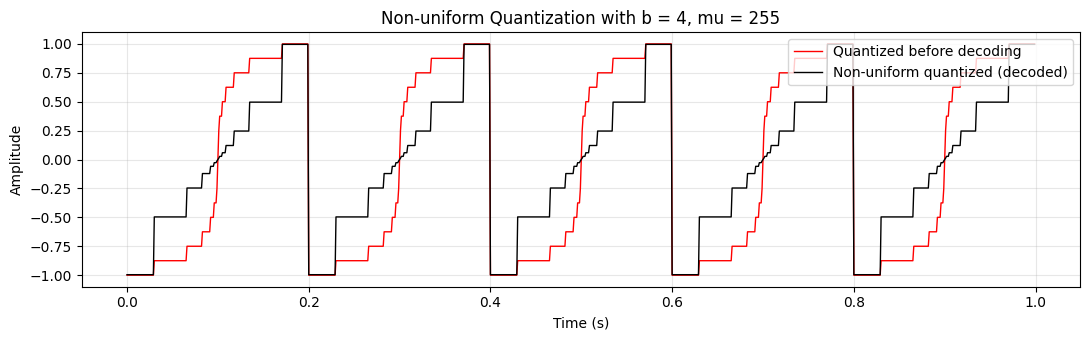

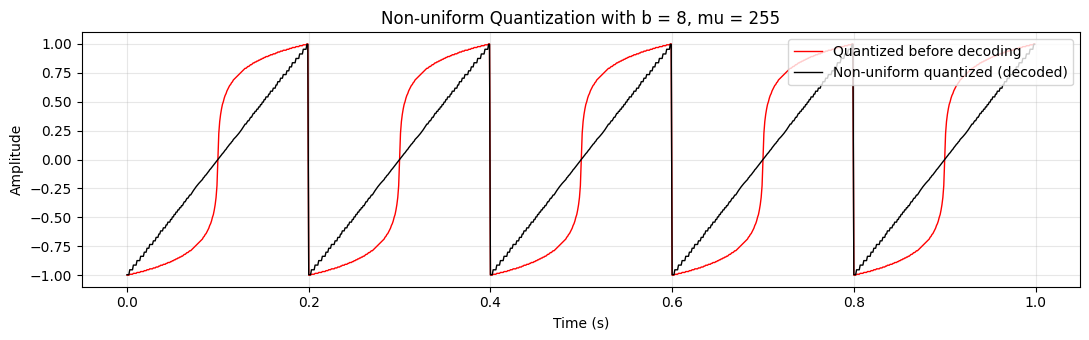

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Step 1: Generate input signal
t1 = np.linspace(0, 1, 1000, endpoint=False)
x = signal.sawtooth(2 * np.pi * 5 * t1)

# Normalisasi ke [-1, 1] untuk mu-law
x_n = x / np.max(np.abs(x))

# Step 2: Mu-law encoding (non-uniform encoding)
mu = 255
y1 = np.sign(x_n) * (np.log(1 + mu * np.abs(x_n)) / np.log(1 + mu))

plt.figure(figsize=(11, 3.5))
plt.plot(t1, x_n, 'b', linewidth=1, label='Input normalized')
plt.plot(t1, y1, 'g', linewidth=1, label='Mu-law encoded')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.legend(loc='upper right')
plt.title(f'Degree of Compression with mu = {mu}')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Step 3: Quantization after encoding
DR = np.max(y1) - np.min(y1)
bits = [1, 2, 4, 8]

for i, b in enumerate(bits):
    L = 2 ** b
    q = DR / L

    # Quantized in compressed domain (mid-tread)
    y2 = np.sign(y1) * q * np.floor((np.abs(y1) / q) + 0.5)

    # Step 4: Mu-law decoding
    y = np.sign(y2) * (((1 + mu) ** (np.abs(y2)) - 1) / mu)

    plt.figure(figsize=(11, 3.5))
    plt.plot(t1, y2, 'r', linewidth=1, label='Quantized before decoding')
    plt.plot(t1, y, 'k', linewidth=1, label='Non-uniform quantized (decoded)')
    plt.xlabel('Time (s)')
    plt.ylabel('Amplitude')
    plt.legend(loc='upper right')
    plt.title(f'Non-uniform Quantization with b = {b}, mu = {mu}')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

**Keterangan**

- Grafik awal: perbandingan sinyal input ter-normalisasi dan hasil kompresi ke dalam mu-law.
- Grafik per bit: sinyal setelah kuantisasi di domain kompresi dan setelah dekompresi.
- Bit yang lebih tinggi membuat distorsi kuantisasi lebih kecil.

**Soal 2 (Jurnal 8):** Amati dan beri komentar perbedaan uniform dan non-uniform companding, serta jelaskan kelebihan dan kekurangan masing-masing berdasarkan hasil error kuantisasi.

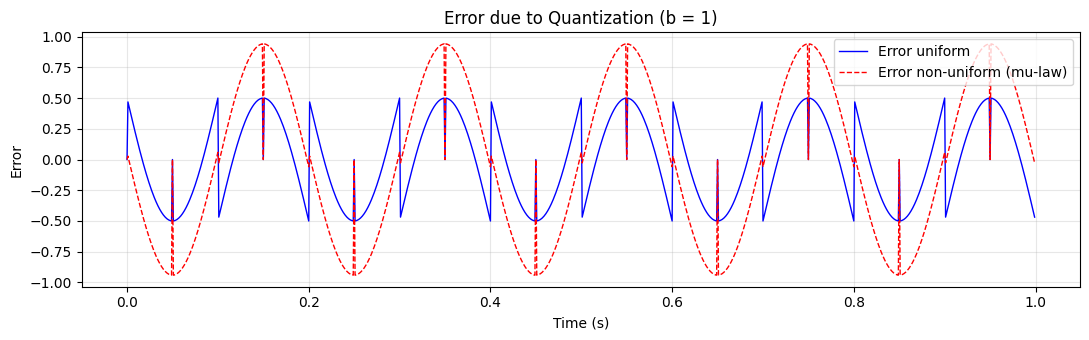

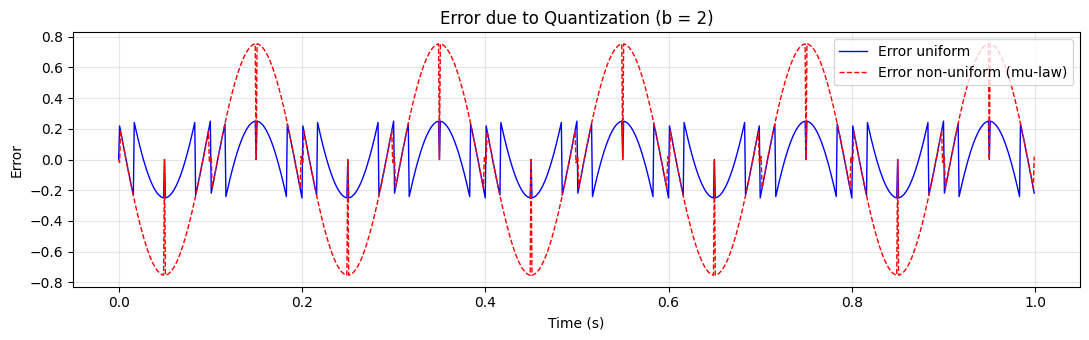

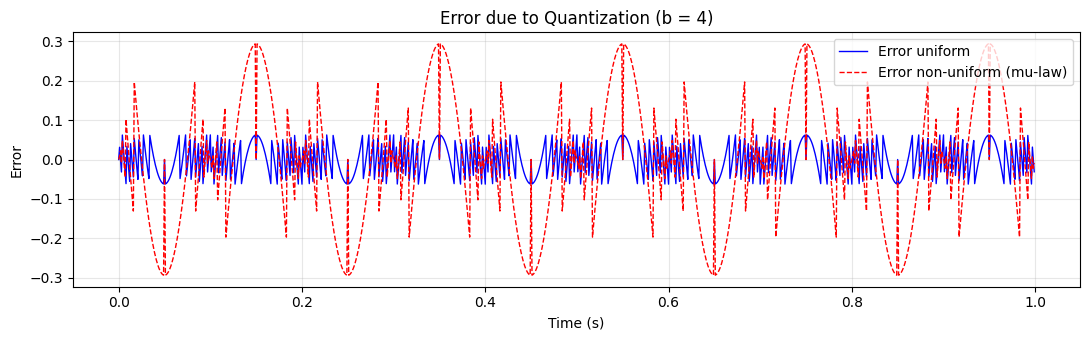

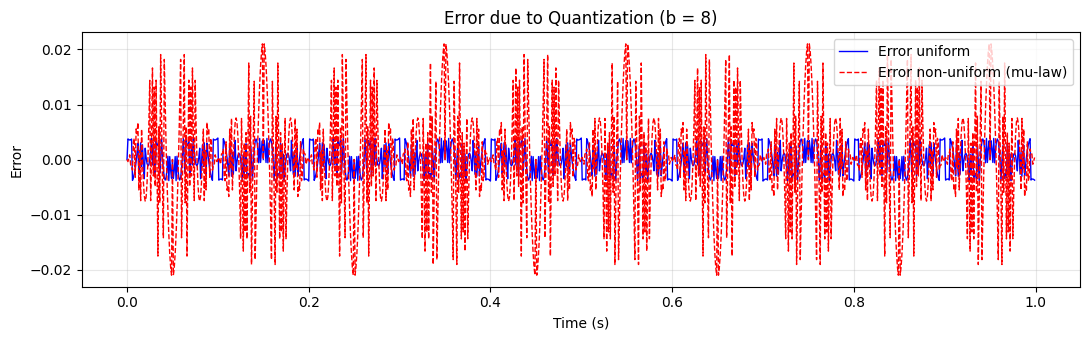

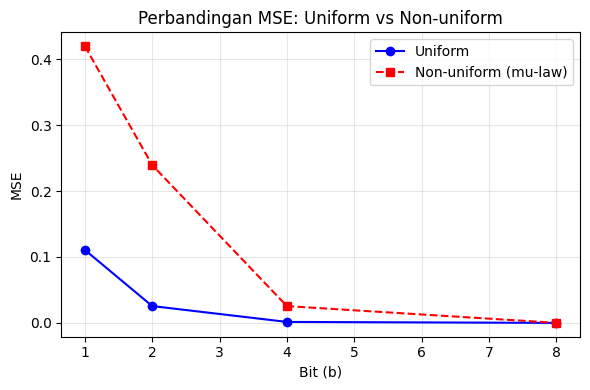

MSE uniform        : [0.11068258837128417, 0.02551805581818377, 0.0014578522142231368, 6.541393610944572e-06]
MSE non-uniform    : [0.4197083321959296, 0.2392981691491761, 0.025431539733878253, 8.651484777769533e-05]

Komentar Jurnal 8:
- Non-uniform (mu-law) memberi resolusi lebih halus pada amplitudo kecil, cocok untuk sinyal suara.
- Uniform lebih sederhana dan linear, tetapi detail amplitudo kecil lebih cepat hilang pada bit rendah.
- Kekurangan non-uniform: butuh proses kompresi-dekompresi tambahan dan implementasi lebih kompleks.
- Pada bit tinggi, perbedaan performa keduanya cenderung mengecil.


In [16]:
import numpy as np
import matplotlib.pyplot as plt

# Input signal
t = np.linspace(0, 1, 1000, endpoint=False)
x = np.sin(2 * np.pi * 5 * t)
x_n = x / np.max(np.abs(x))

bits = [1, 2, 4, 8]
mu = 255

mse_uniform = []
mse_nonuniform = []

for i, b in enumerate(bits):
    L = 2 ** b

    # Uniform quantization (mid-rise sederhana)
    q_u = 2 / L
    y_u = np.sign(x_n) * q_u * (np.floor(np.abs(x_n) / q_u) + 0.5)
    y_u = np.clip(y_u, -1, 1)
    e_u = y_u - x_n
    mse_uniform.append(np.mean(e_u ** 2))

    # Non-uniform quantization via mu-law companding
    y_enc = np.sign(x_n) * (np.log(1 + mu * np.abs(x_n)) / np.log(1 + mu))
    q_c = 2 / L
    y_qc = np.sign(y_enc) * q_c * (np.floor(np.abs(y_enc) / q_c) + 0.5)
    y_qc = np.clip(y_qc, -1, 1)
    y_dec = np.sign(y_qc) * (((1 + mu) ** (np.abs(y_qc)) - 1) / mu)
    e_nu = y_dec - x_n
    mse_nonuniform.append(np.mean(e_nu ** 2))

    # Plot error signal untuk tiap b
    plt.figure(figsize=(11, 3.5))
    plt.plot(t, e_u, 'b', linewidth=1, label='Error uniform')
    plt.plot(t, e_nu, 'r--', linewidth=1, label='Error non-uniform (mu-law)')
    plt.xlabel('Time (s)')
    plt.ylabel('Error')
    plt.title(f'Error due to Quantization (b = {b})')
    plt.legend(loc='upper right')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# Ringkasan MSE
plt.figure(figsize=(6, 4))
plt.plot(bits, mse_uniform, 'bo-', label='Uniform')
plt.plot(bits, mse_nonuniform, 'rs--', label='Non-uniform (mu-law)')
plt.xlabel('Bit (b)')
plt.ylabel('MSE')
plt.title('Perbandingan MSE: Uniform vs Non-uniform')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print('MSE uniform        :', [float(v) for v in mse_uniform])
print('MSE non-uniform    :', [float(v) for v in mse_nonuniform])

print('\nKomentar Jurnal 8:')
print('- Non-uniform (mu-law) memberi resolusi lebih halus pada amplitudo kecil, cocok untuk sinyal suara.')
print('- Uniform lebih sederhana dan linear, tetapi detail amplitudo kecil lebih cepat hilang pada bit rendah.')
print('- Kekurangan non-uniform: butuh proses kompresi-dekompresi tambahan dan implementasi lebih kompleks.')
print('- Pada bit tinggi, perbedaan performa keduanya cenderung mengecil.')

**Keterangan

- Grafik per bit: perbandingan error uniform dan error non-uniform (mu-law).
- Grafik MSE: ringkasan error rata-rata terhadap jumlah bit.
- Umumnya, saat bit bertambah, MSE kedua metode menurun.

## Kesimpulan

1.Sampling adalah proses mengubah sinyal kontinu menjadi sinyal diskrit. Nilai periode sampling (T) sangat berpengaruh terhadap kerapatan data—semakin kecil T, semakin rapat data yang dihasilkan.
2.Pada comb function, komponen frekuensi muncul pada kelipatan frekuensi dasar. Perbedaan antara C1 dan C2 terjadi karena perbedaan periode, sehingga pola frekuensinya juga berbeda.
3.Jika frekuensi sampling terlalu rendah, maka akan terjadi aliasing, yaitu kondisi di mana sinyal yang terbaca tidak sesuai dengan sinyal aslinya.
4.Kuantisasi adalah proses mengubah nilai amplitudo menjadi beberapa level tertentu. Semakin besar jumlah bit yang digunakan, hasil sinyal akan semakin halus dan kesalahan (error) semakin kecil.
5.Perbandingan antara mid-tread dan mid-rise menunjukkan bahwa keduanya memberikan hasil yang lebih baik saat jumlah bit meningkat, namun memiliki perbedaan dalam merepresentasikan nilai di sekitar nol.
6.Pada audio dan citra, penggunaan jumlah bit yang kecil akan menurunkan kualitas, sedangkan jumlah bit yang lebih besar menghasilkan kualitas yang lebih mendekati data asli.
7.Non-uniform quantization (mu-law) digunakan untuk mempertahankan detail pada sinyal dengan amplitudo kecil, sehingga sangat efektif untuk sinyal suara.